# Week 10 · Robust Federated Learning Lab
**Course:** Theory and Applications of Federated Learning  
**Instructor:** Faranak Solat, Sejong University

We train a digit classifier with simulated clients. Some clients reverse and scale their own model updates. We compare the mean, coordinate-wise median, and trimmed mean.

**Run in Google Colab:** upload this `.ipynb`, select a CPU runtime, then choose **Runtime → Run all**. The standard Colab environment includes the packages below. No account, GPU, or dataset download is needed. This is a local simulation, not a networked FL system.

**Class demo (5–7 minutes):** show the data plot, explain `local_update`, `aggregate`, and the attack line, then discuss the results. You do not need to type or explain every line.

**Scope:** this lab studies an untargeted model-poisoning attack. It does not implement a backdoor, privacy protection, or a formal robustness guarantee.


In [1]:
import sys, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score
try:
    from IPython.display import display
except ImportError:
    display = print
print('Python:', sys.version.split()[0], '| NumPy:', np.__version__, '| sklearn:', sklearn.__version__)
SEEDS = [11, 22, 33]
N_CLIENTS, N_BAD = 20, 4
ROUNDS, LOCAL_STEPS, LR = 50, 3, 0.3
ATTACK_SCALE, TRIM, ALPHA = 8.0, 4, 0.5
assert 0 <= 2 * TRIM < N_CLIENTS
assert N_BAD <= TRIM


Python: 3.12.14 | NumPy: 2.3.5 | sklearn: 1.8.0


## 1. Data and client partitions
`load_digits` contains 1,797 small 8 × 8 digit images with labels 0–9. Pixel values range from 0 to 16. We divide by 16 and add a constant feature for the bias.

Each seed creates a stratified 75% training / 25% test split. The test data never enters local training or parameter selection. We compare an IID random split with a non-IID label split drawn from a Dirichlet distribution. Smaller `ALPHA` usually gives stronger label imbalance. We retry the non-IID split until every client has at least 20 examples.

Clients can have different sample counts. All aggregators give each participating client one vote. Therefore the mean is an **equal-client baseline**, not the usual sample-count-weighted FedAvg. This choice isolates the aggregation rule.


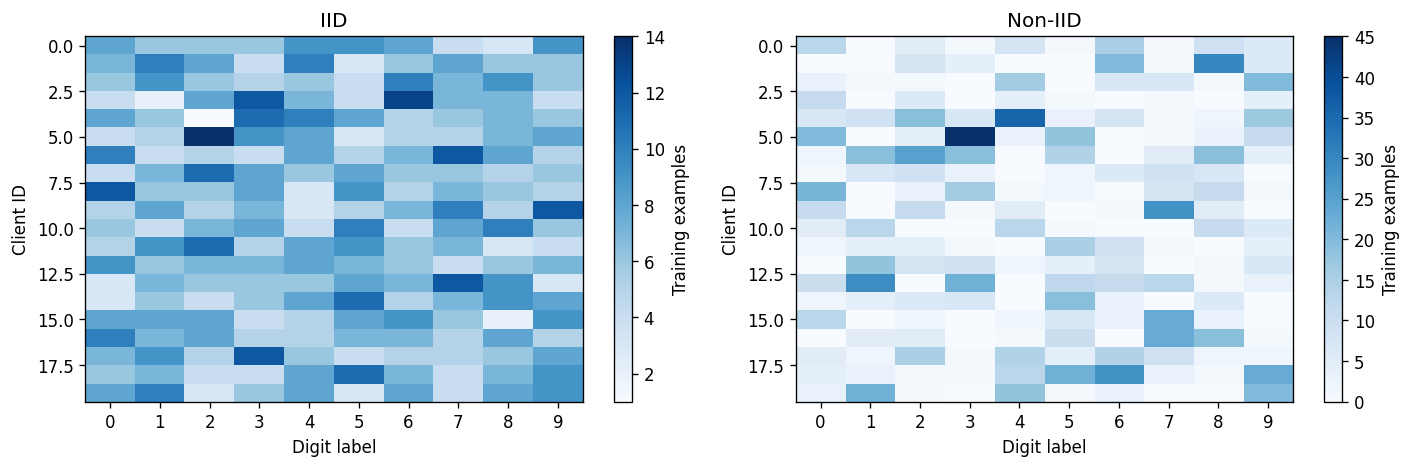

In [2]:
def make_data(seed, partition):
    digits = load_digits()
    X = np.column_stack([digits.data / 16.0, np.ones(len(digits.target))])
    Xtr, Xte, ytr, yte = train_test_split(
        X, digits.target, test_size=0.25, stratify=digits.target, random_state=seed)
    rng = np.random.default_rng(seed)
    if partition == 'IID':
        clients = list(np.array_split(rng.permutation(len(ytr)), N_CLIENTS))
    else:
        for attempt in range(1000):
            groups = [[] for _ in range(N_CLIENTS)]
            for label in range(10):
                ids = rng.permutation(np.flatnonzero(ytr == label))
                shares = rng.dirichlet(np.full(N_CLIENTS, ALPHA))
                counts = rng.multinomial(len(ids), shares)
                for k, part in enumerate(np.split(ids, np.cumsum(counts)[:-1])):
                    groups[k].extend(part.tolist())
            if min(map(len, groups)) >= 20:
                clients = [np.asarray(g, dtype=int) for g in groups]
                break
        else:
            raise RuntimeError('Could not create partition; increase ALPHA.')
    joined = np.concatenate(clients)
    assert len(joined) == len(ytr) and len(np.unique(joined)) == len(ytr)
    return Xtr, Xte, ytr, yte, clients

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, part in zip(axes, ['IID', 'Non-IID']):
    Xtr, Xte, ytr, yte, clients = make_data(SEEDS[0], part)
    counts = np.array([np.bincount(ytr[idx], minlength=10) for idx in clients])
    im = ax.imshow(counts, aspect='auto', cmap='Blues')
    ax.set(title=part, xlabel='Digit label', ylabel='Client ID', xticks=range(10))
    fig.colorbar(im, ax=ax, label='Training examples')
plt.tight_layout()
plt.show()


## 2. Local training
The model is softmax regression. Each client starts from the same global weights and takes a few full-batch gradient steps on its own data.

Its message is a **model delta**: $\Delta_k = W_k - W$. The server adds an aggregated delta to the current model. This is why the update has a plus sign.

Softmax probabilities use a numerical stability step: subtract the largest score before taking the exponential.


In [3]:
def probabilities(X, W):
    scores = X @ W
    scores -= scores.max(axis=1, keepdims=True)
    exp_scores = np.exp(scores)
    return exp_scores / exp_scores.sum(axis=1, keepdims=True)

def local_update(W, X, y):
    local = W.copy()
    target = np.eye(10)[y]
    for _ in range(LOCAL_STEPS):
        gradient = X.T @ (probabilities(X, local) - target) / len(y)
        local -= LR * gradient
    return local - W


## 3. Aggregation rules
For $n$ client updates and coordinate $j$:

- **Mean:** $a_j = \frac{1}{n}\sum_{k=1}^{n}\Delta_{k,j}$.
- **Median:** $a_j = \mathrm{median}_k(\Delta_{k,j})$. For even $n$, NumPy averages the two middle values.
- **Trimmed mean:** sort each coordinate, remove the smallest and largest $b$ values, and average the remaining $n-2b$ values.

Here $n=20$ and $b=4$. We retain 12 values per coordinate. Different coordinates may retain values from different clients. The server does **not** identify and remove four whole malicious clients. Knowing an upper bound on the attack count does not guarantee success under arbitrary non-IID data.


In [4]:
def aggregate(updates, rule, trim=TRIM):
    updates = np.asarray(updates)
    if rule == 'Mean':
        return updates.mean(axis=0)
    if rule == 'Median':
        return np.median(updates, axis=0)
    if rule == 'Trimmed mean':
        if not 0 <= 2 * trim < len(updates):
            raise ValueError('Need 0 <= 2 * trim < number of clients')
        ordered = np.sort(updates, axis=0)
        retained = ordered if trim == 0 else ordered[trim:-trim]
        return retained.mean(axis=0)
    raise ValueError('Unknown aggregation rule')

# A small exact example checks the axis and trimming behavior.
toy = np.array([[0.8], [0.9], [1.0], [1.1], [1.2], [1.3], [9.0]])
assert np.isclose(aggregate(toy, 'Mean')[0], 15.3 / 7)
assert np.isclose(aggregate(toy, 'Median')[0], 1.1)
assert np.isclose(aggregate(toy, 'Trimmed mean', trim=1)[0], 1.1)
assert np.allclose(aggregate(toy, 'Trimmed mean', trim=0), toy.mean(axis=0))
print('Aggregation checks passed.')


Aggregation checks passed.


## 4. Attack and federated rounds
All 20 clients participate in every round. For each seed, the attacker controls the same four client IDs in every experiment. Each malicious client sends $-8\Delta_k$ in place of its own delta. This is a simple **sign-flip and scaling attack**, aimed at reducing overall accuracy.

The attacker knows its own delta and the fixed scale. It does not use honest clients’ updates or adapt to the defense. The server sees individual updates. We assume no secure aggregation and no clipping in this lab.

For a fair comparison, the rules share the split, partition, attacker IDs, zero initialization, and local training settings for each seed. Later training paths naturally differ because the global models differ.


In [5]:
def run_experiment(seed, partition, rule, attacked):
    Xtr, Xte, ytr, yte, clients = make_data(seed, partition)
    bad = set(np.random.default_rng(seed + 1000).choice(N_CLIENTS, N_BAD, replace=False))
    W = np.zeros((Xtr.shape[1], 10))
    rows = []
    for round_id in range(ROUNDS + 1):
        prob = probabilities(Xte, W)
        pred = prob.argmax(axis=1)
        rows.append(dict(seed=seed, partition=partition, rule=rule,
                         attack='Sign flip' if attacked else 'Clean', round=round_id,
                         accuracy=accuracy_score(yte, pred),
                         macro_f1=f1_score(yte, pred, average='macro', zero_division=0),
                         loss=-np.log(np.clip(prob[np.arange(len(yte)), yte], 1e-12, 1)).mean()))
        if round_id == ROUNDS:
            break
        updates = []
        for k, ids in enumerate(clients):
            delta = local_update(W, Xtr[ids], ytr[ids])
            if attacked and k in bad:
                delta = -ATTACK_SCALE * delta  # The attack changes the transmitted update.
            updates.append(delta)
        W += aggregate(updates, rule)
        assert np.isfinite(W).all()
    return rows


## 5. Run the controlled comparison
We run all three rules both with and without the attack, on IID and non-IID data, across three seeds: 36 training runs. CPU execution is sufficient. Results are computed below; no accuracy values are hard-coded.

The clean run of **each rule** is essential. A defense can reduce attack damage but also reduce clean accuracy. We keep all hyperparameters fixed in advance. Test curves illustrate behavior and are not used to choose settings.


In [6]:
start = time.perf_counter()
records = []
for seed in SEEDS:
    for partition in ['IID', 'Non-IID']:
        for rule in ['Mean', 'Median', 'Trimmed mean']:
            for attacked in [False, True]:
                records.extend(run_experiment(seed, partition, rule, attacked))
results = pd.DataFrame(records)
print(f'Completed 36 runs in {time.perf_counter() - start:.1f} seconds.')
final = results[results['round'] == ROUNDS]
summary = final.groupby(['partition', 'rule', 'attack']).agg(
    accuracy_mean=('accuracy', 'mean'), accuracy_sd=('accuracy', 'std'),
    macro_f1_mean=('macro_f1', 'mean'), loss_mean=('loss', 'mean')).reset_index()
display(summary.round(4))


Completed 36 runs in 6.2 seconds.


,partition,rule,attack,accuracy_mean,accuracy_sd,macro_f1_mean,loss_mean
0,IID,Mean,Clean,0.9267,0.0097,0.9269,0.4548
1,IID,Mean,Sign flip,0.0993,0.0034,0.0181,24.8884
2,IID,Median,Clean,0.9215,0.0122,0.9219,0.4557
3,IID,Median,Sign flip,0.9244,0.0080,0.9250,0.5196
4,IID,Trimmed mean,Clean,0.9237,0.0122,0.9241,0.4552
5,IID,Trimmed mean,Sign flip,0.9222,0.0080,0.9227,0.5326
6,Non-IID,Mean,Clean,0.9274,0.0151,0.9277,0.4961
7,Non-IID,Mean,Sign flip,0.1007,0.0013,0.0183,24.8475
8,Non-IID,Median,Clean,0.8667,0.0366,0.8637,0.7736
9,Non-IID,Median,Sign flip,0.7363,0.0433,0.6709,1.0021


## 6. Learning curves and attack damage
Lines show mean test accuracy across three seeds. Shaded bands show one sample standard deviation, not confidence intervals.

Compare clean and attacked runs for the same rule. Also compare each clean defense with the clean mean. A high final accuracy in this one experiment does not establish safety against other attacks.


Saved results as CSV files in the current runtime.


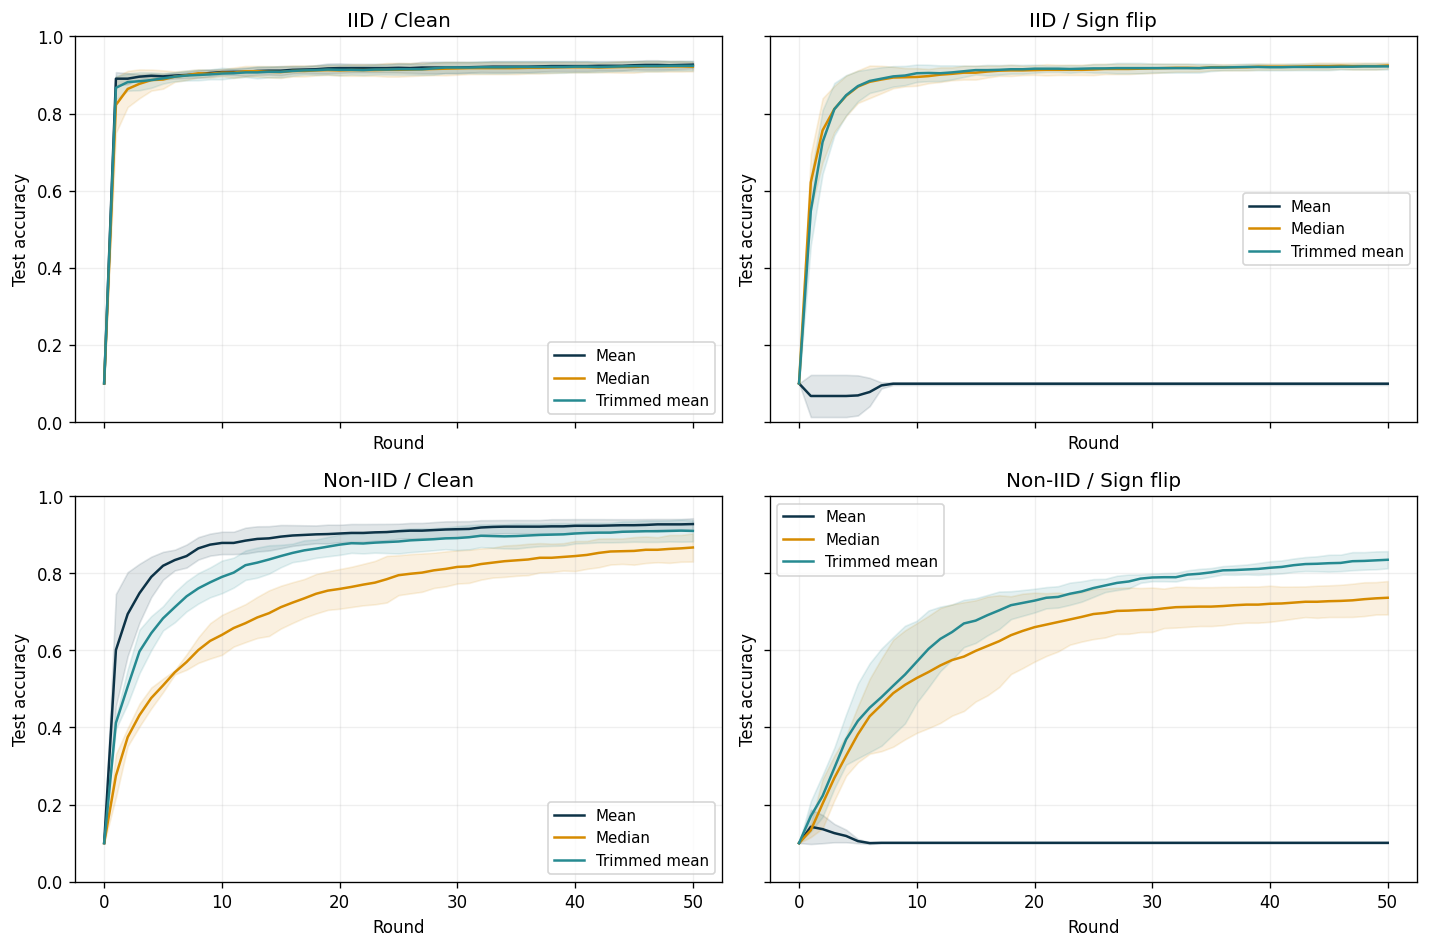

mean   std
partition rule                     
IID       Mean          82.74  0.93
          Median        -0.30  0.78
          Trimmed mean   0.15  0.78
Non-IID   Mean          82.67  1.60
          Median        13.04  4.57
          Trimmed mean   7.48  1.30

In [7]:
colors = {'Mean': '#0D3347', 'Median': '#D68B00', 'Trimmed mean': '#268A91'}
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True)
for row, partition in enumerate(['IID', 'Non-IID']):
    for col, attack in enumerate(['Clean', 'Sign flip']):
        ax = axes[row, col]
        for rule in colors:
            subset = results[(results.partition == partition) & (results.attack == attack) & (results.rule == rule)]
            curve = subset.groupby('round').accuracy.agg(['mean', 'std'])
            x, mean, sd = curve.index.to_numpy(), curve['mean'].to_numpy(), curve['std'].to_numpy()
            ax.plot(x, mean, label=rule, color=colors[rule])
            ax.fill_between(x, np.maximum(0, mean-sd), np.minimum(1, mean+sd), color=colors[rule], alpha=0.12)
        ax.set(title=f'{partition} / {attack}', xlabel='Round', ylabel='Test accuracy', ylim=(0, 1))
        ax.grid(alpha=0.2)
        ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

paired = final.pivot(index=['seed', 'partition', 'rule'], columns='attack', values='accuracy').reset_index()
paired['attack_drop_pp'] = 100 * (paired['Clean'] - paired['Sign flip'])
display(paired.groupby(['partition', 'rule']).attack_drop_pp.agg(['mean', 'std']).round(2))
results.to_csv('week10_all_rounds.csv', index=False)
summary.to_csv('week10_summary.csv', index=False)
print('Saved results as CSV files in the current runtime.')


## 7. Discussion and research extensions
1. Which method loses the most accuracy under this attack? Use the paired attack-drop table.
2. Does median or trimmed mean reduce clean accuracy on non-IID data? Why might honest updates disagree?
3. Why is “20% malicious clients” different from “20% of training examples”?
4. Would this experiment detect a backdoor? **No.** A backdoor study also needs a trigger definition, target label, and attack success rate on eligible triggered inputs.
5. What changes if clients participate only sometimes? The malicious fraction among selected clients can differ from the population fraction.

For an extension, change one factor at a time: `ALPHA`, `N_BAD`, `ATTACK_SCALE`, or `TRIM`. If changing the attack budget, update or remove the `N_BAD <= TRIM` assumption check deliberately and explain the new setting. Use a separate validation set for tuning, then evaluate once on held-out test data. Add more seeds and class-level metrics before making a research claim.

**Limits:** small public dataset, simulated clients, full participation, fixed attacker identities, one simple attack, no backdoor, and no formal convergence or robustness proof. Coordinate-wise defenses may discard useful honest variation. A stronger adaptive attack may behave differently.

## References
- Yin et al. (2018), *Byzantine-Robust Distributed Learning: Towards Optimal Statistical Rates*. https://proceedings.mlr.press/v80/yin18a.html
- Blanchard et al. (2017), *Machine Learning with Adversaries: Byzantine Tolerant Gradient Descent*. https://papers.neurips.cc/paper/2017/hash/f4b9ec30ad9f68f89b29639786cb62ef-Abstract.html
- Bagdasaryan et al. (2020), *How To Backdoor Federated Learning*. https://proceedings.mlr.press/v108/bagdasaryan20a.html
- scikit-learn digits dataset documentation: https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html

The lab applies simple aggregation ideas for teaching. It does not reproduce the theoretical settings or experiments of these papers.
